# Provision of Chemicals I

The pharmaceutical company Boring International wants to optimize the supply of chemical raw materials to its premises from an external warehouse. Each day is divided into specific time units. At each time unit, there may be a demand for a specific raw material at the facility. To cover this demand, a truck operates between the external warehouse and the facility premises. Raw materials transported by the truck can either be used directly to meet current demand or stored in intermediate storage to satisfy future demand. The intermediate storage has a limited storage capacity, and the truck also has a limited transport capacity. The external warehouse is close: the truck can make one delivery every time unit.

Each trip incurs costs. These costs should be minimized.

Each instance is characterized by the following data:
* The set of raw materials (chemicals): $\mathcal C$
* Capacity of intermediate storage: $B$
* Time periods: $0,...,T-1$
* Demand at time $t$ for raw material $c$: $d_{ct}$
* Cost of a single trip: $g$
* Capacity of the delivery truck: $h$


Variables:
* $z_t \in \{0,1\}$: Indicator whether a delivery takes place at time $t$
* $x_{ct} \geq 0$: Amount of raw material $c$ delivered at the beginning of period $t$
* $p_{ct} \geq 0$: Amount of raw material $c$ present in intermediate storage at the end of period $t$


We load the necessary files and import the required modules. The output may look complicated -- simply ignore it! If you are working locally on your machine, have `mip` installed, and placed `chm.py` in the same directory, comment out the first two lines.

In [1]:
!wget -q https://raw.githubusercontent.com/henningbruhn/mobp/main/chem_aufgabe/chm.py
!pip install mip # NOTE: this is for the Colab version to avoid conflicts with package cffi
#!pip install mip

import mip   ## The MIP solver
import chm   ## Code for instance generation and graphical visualization

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

We acquire the instance `inst` that you should work with.

In [2]:
inst=chm.get_instance1()
print(inst)

C Anzahl Rohstoffe: ...................3
T Anzahl Zeitperioden: ................11
B Kapazität des Zwischenlagers: .......100
g Kosten einer Fahrt: .................1
h Kapazität des Lastwagens: ...........50
d Gesamtbedarf über alle Zeitperioden: 196.0



The attributes allow access to the respective parameters. For example, the number of raw materials can be accessed via `inst.C`. Let's inspect the demand matrix:

In [3]:
inst.d

[[0.0, 0.0, 0.0, 0.0, 45.0, 0.0, 12.0, 0.0, 0.0, 0.0, 6.0],
 [0.0, 0.0, 0.0, 0.0, 22.0, 0.0, 0.0, 20.0, 0.0, 19.0, 0.0],
 [0.0, 0.0, 0.0, 13.0, 0.0, 0.0, 0.0, 0.0, 11.0, 0.0, 48.0]]

The demand is stored such that `inst.d[c][t]` quantifies the demand for raw material `c` at time `t`.

There is also a function to plot the demand. The raw materials are arbitrarily named after real chemicals.

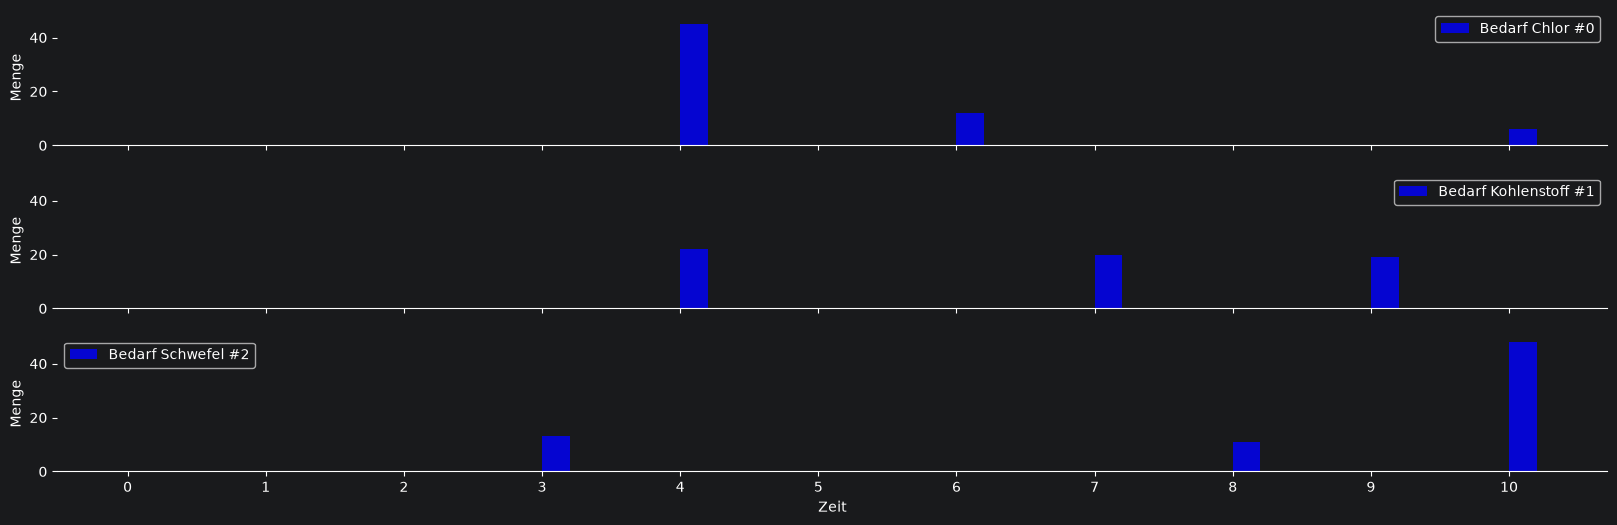

In [4]:
chm.show_demand(inst)

We start by initializing the variables:

In [5]:
m=mip.Model()
# Additional variable at period T so that p[c][-1] is defined
p=[[m.add_var() for _ in range(inst.T+1)] for _ in range(inst.C)]   # put in intermediate storage
x=[[m.add_var() for _ in range(inst.T)] for _ in range(inst.C)]     # delivered materials
z=[m.add_var(var_type=mip.BINARY) for _ in range(inst.T)]           # binary: does delivery take place at time t?

A small tip: For a list `L`, Python allows writing `L[-1]` to access the last element. In our case, we appended an additional variable at the end of `p` to represent the inventory state before work begins.

**Implement your MIP here:**

In [6]:
for t in range(inst.T):
    # End-of-period inventory cannot exceed storage capacity B:
    m += mip.xsum(p[c][t] for c in range(inst.C)) <= inst.B

    # Transport capacity of truck cannot be exceeded at any time t:
    m += mip.xsum(x[c][t] for c in range(inst.C)) <= inst.h * z[t]

    for c in range(inst.C):
        # Nothing is in intermediate storage at the start:
        m += p[c][inst.T] == 0

        # Demand must be met for every chemical c:
        m += x[c][t] + p[c][t-1] >= inst.d[c][t]

        # Delivered amount of each chemical c at every time t must be put in intermediate storage or used:
        m += p[c][t] == p[c][t - 1] + x[c][t] - inst.d[c][t]
m.objective = mip.minimize(inst.g * mip.xsum(z[t] for t in range(inst.T)))

We start optimization using `optimize()`. We also print the optimization status and total cost.

In [7]:
m.verbose=0 # suppress solver output
opt_status=m.optimize()
print("Optimization status: {}".format(opt_status))
print("Total cost: {}".format(m.objective_value))

Optimization status: OptimizationStatus.OPTIMAL
Total cost: 4.0


Graphical visualization of the solution. By setting `chemical` to specific raw material indices (e.g., `chemical=1`), you can inspect demand/inventory/deliveries for individual raw materials.

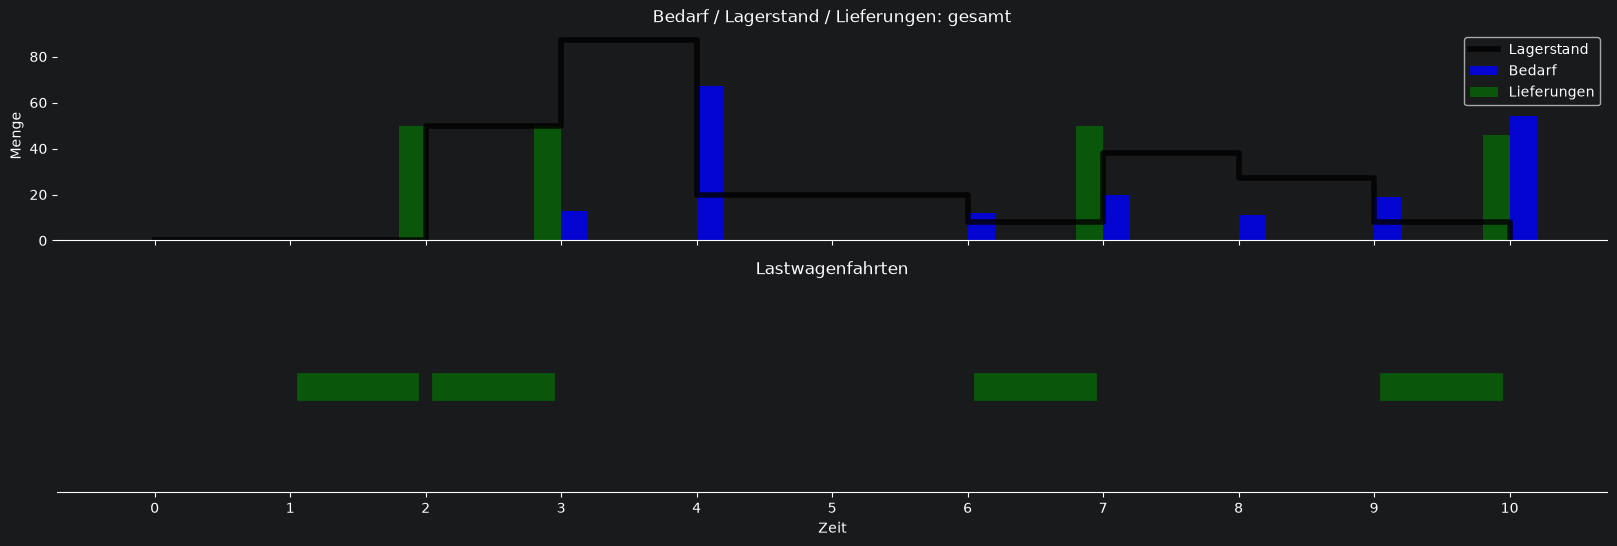

In [8]:
chm.show_solution1(x,z,p,inst,chemical='all')